# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the Siri Whu dataset.

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SiriWhuDataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/SIRI-WHU", 
    "csv_file": "./data/SIRI-WHU/siriwhu_train.csv"
    }
dataset = SiriWhuDataset(dataset_config)

## Show images from the dataset

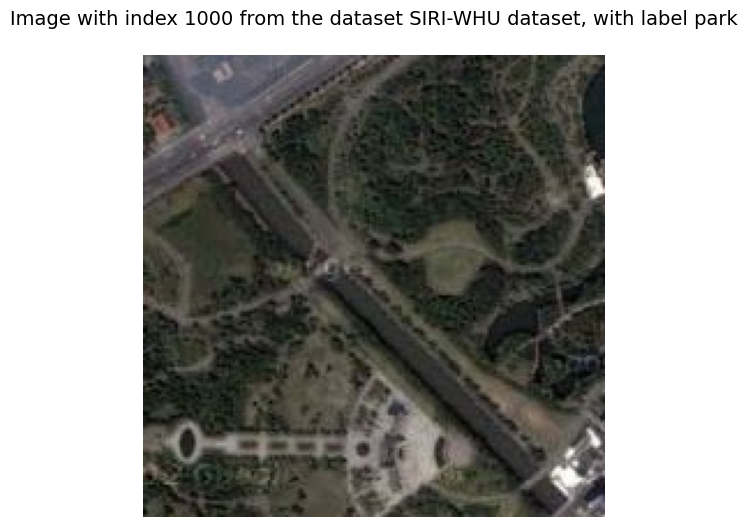

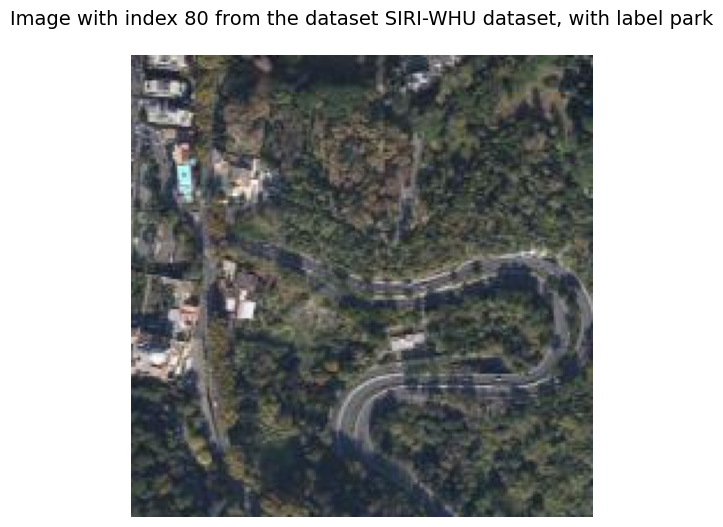

In [7]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(80)

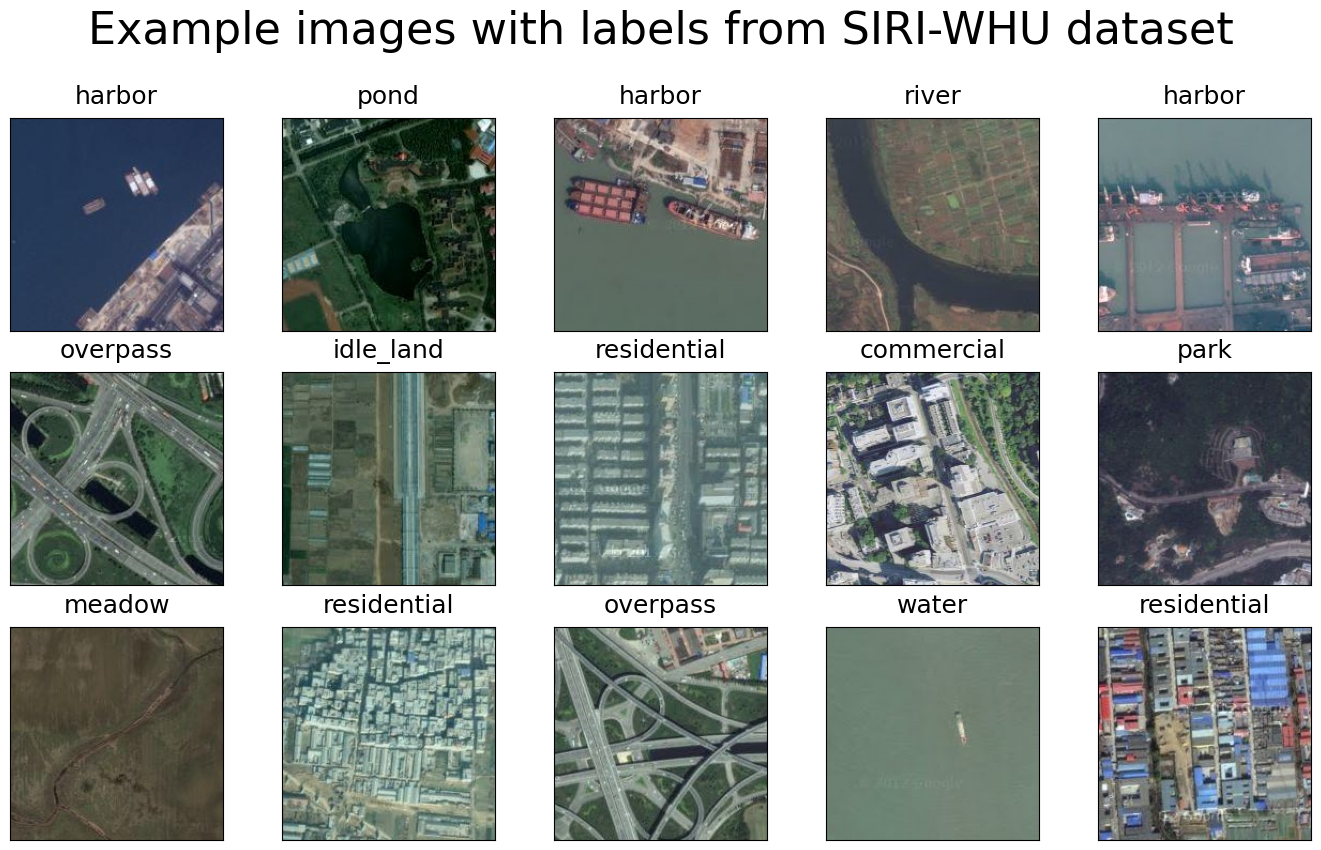

In [8]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [9]:
dataset.show_samples()

,File name,Label
0,river/0064.tif,river
1,residential/0145.tif,residential
2,meadow/0065.tif,meadow
3,overpass/0075.tif,overpass
4,overpass/0036.tif,overpass
5,industrial/0074.tif,industrial
6,water/0040.tif,water
7,river/0023.tif,river
8,water/0198.tif,water
9,commercial/0106.tif,commercial


In [10]:
dataset.data_distribution_table()

,Label,Count
0,agriculture,120
1,commercial,120
2,harbor,120
3,idle_land,120
4,industrial,120
5,meadow,120
6,overpass,120
7,park,120
8,pond,120
9,residential,120


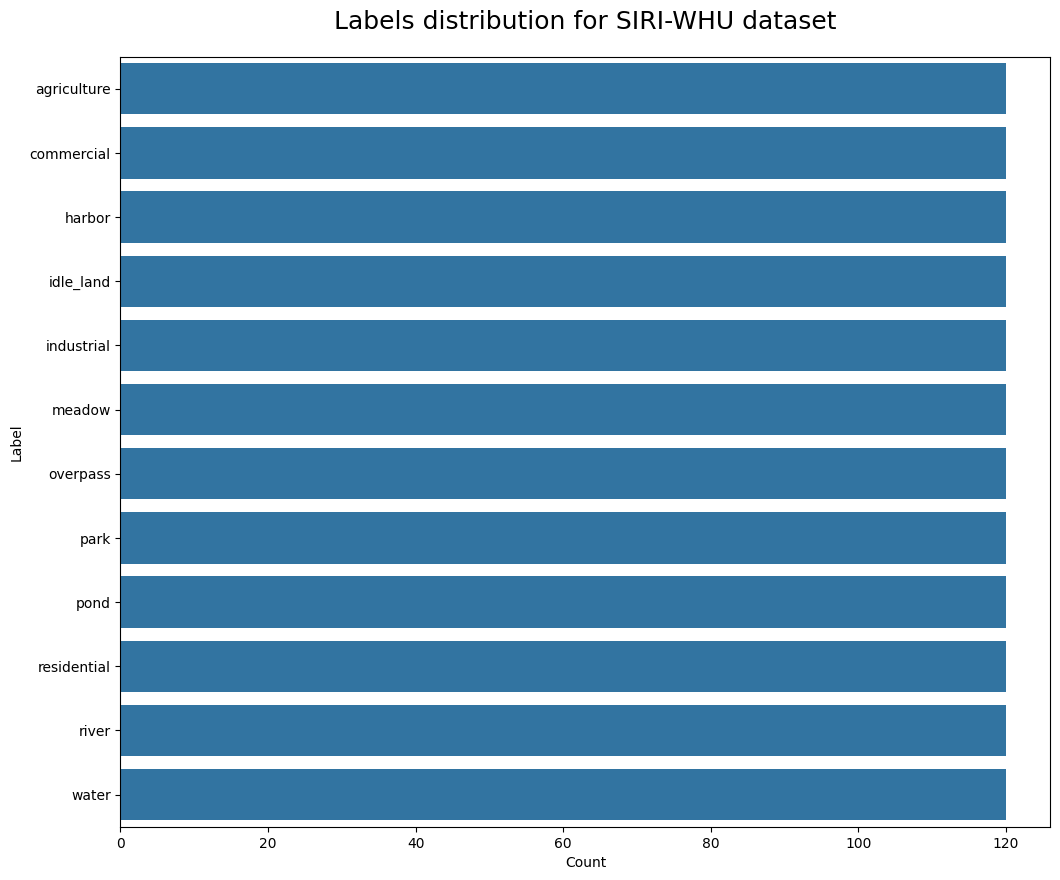

In [11]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/SIRI-WHU",
    "csv_file": "./data/SIRI-WHU/siriwhu_train.csv",
}

train_dataset = SiriWhuDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/SIRI-WHU",
    "csv_file": "./data/SIRI-WHU/siriwhu_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = SiriWhuDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(1440, 480)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/SIRI-WHU"
model_config = {
    "num_classes": 12,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [17]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 12:50:36,402 INFO Starting training.
training: 100%|██████████| 90/90 [00:04<00:00, 19.67it/s]
2026-08-24 12:50:41,050 INFO epoch: 1, time: 5, loss:  2.07979
testing on train set: 100%|██████████| 90/90 [00:02<00:00, 32.64it/s]
2026-08-24 12:50:44,678 INFO Accuracy:0.8111111111111111, Precision Micro:0.8111111111111111, Precision Macro:0.8231129553425678, Precision Weighted:0.8231129553425678, Precision per Class:[0.78195489 0.75816993 0.8442623  0.97674419 0.81751825 0.84946237
 0.80272109 0.74626866 0.85714286 0.87903226 0.71900826 0.84507042], Recall Micro:0.8111111111111111, Recall Macro:0.8111111111111112, Recall Weighted:0.8111111111111111, Recall per Class:[0.86666667 0.96666667 0.85833333 0.35       0.93333333 0.65833333
 0.98333333 0.83333333 0.65       0.90833333 0.725      1.        ], F1_score Micro:0.8111111111111106, F1_score Macro:0.799500479627337, F1_score Weighted:0.7995004796273368, F1_score per Class:[0.82213439 0.84981685 0.85123967 0.51533742 0.87159533

0.09879000532544321

## Predictions

2026-08-24 12:52:13,818 INFO Loading checkpoint /home/dragik/data/experiments/SIRI-WHU/checkpoint.pth.tar
2026-08-24 12:52:14,177 INFO Loaded checkpoint /home/dragik/data/experiments/SIRI-WHU/checkpoint.pth.tar at epoch 11


480


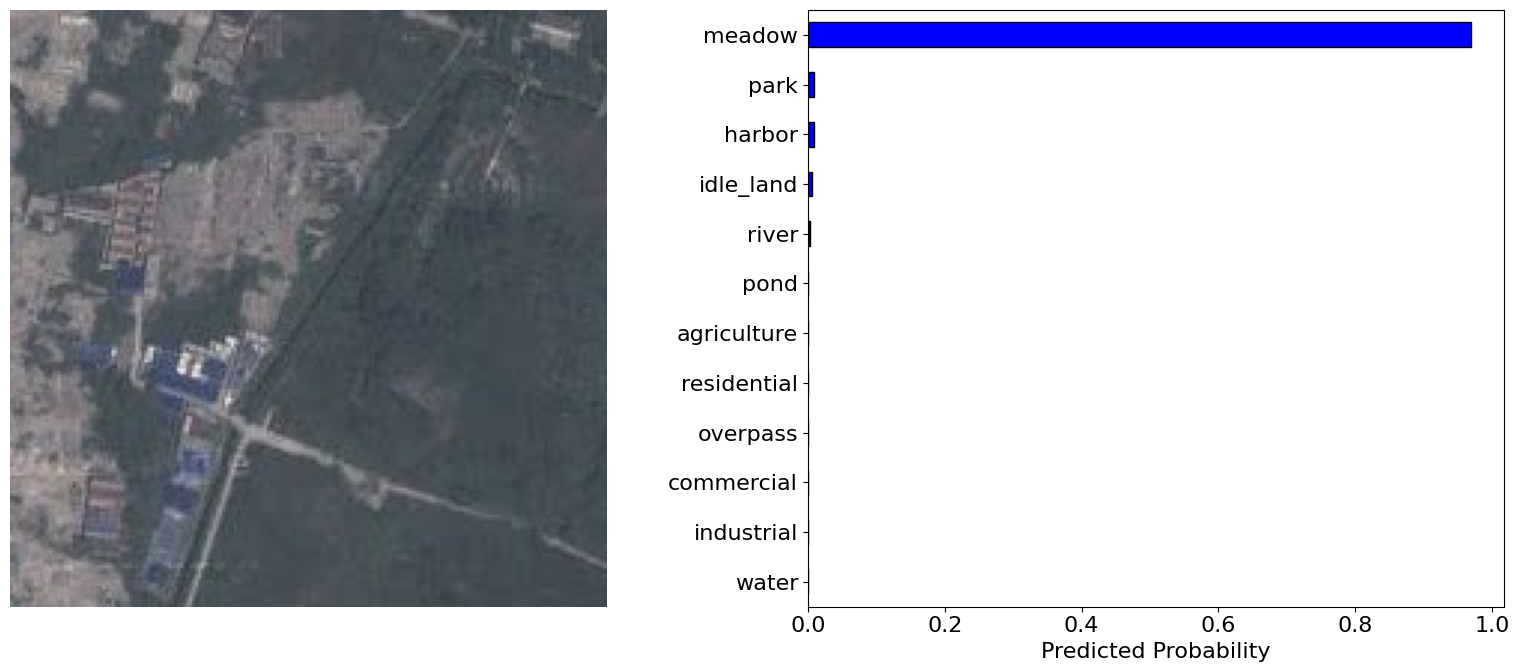

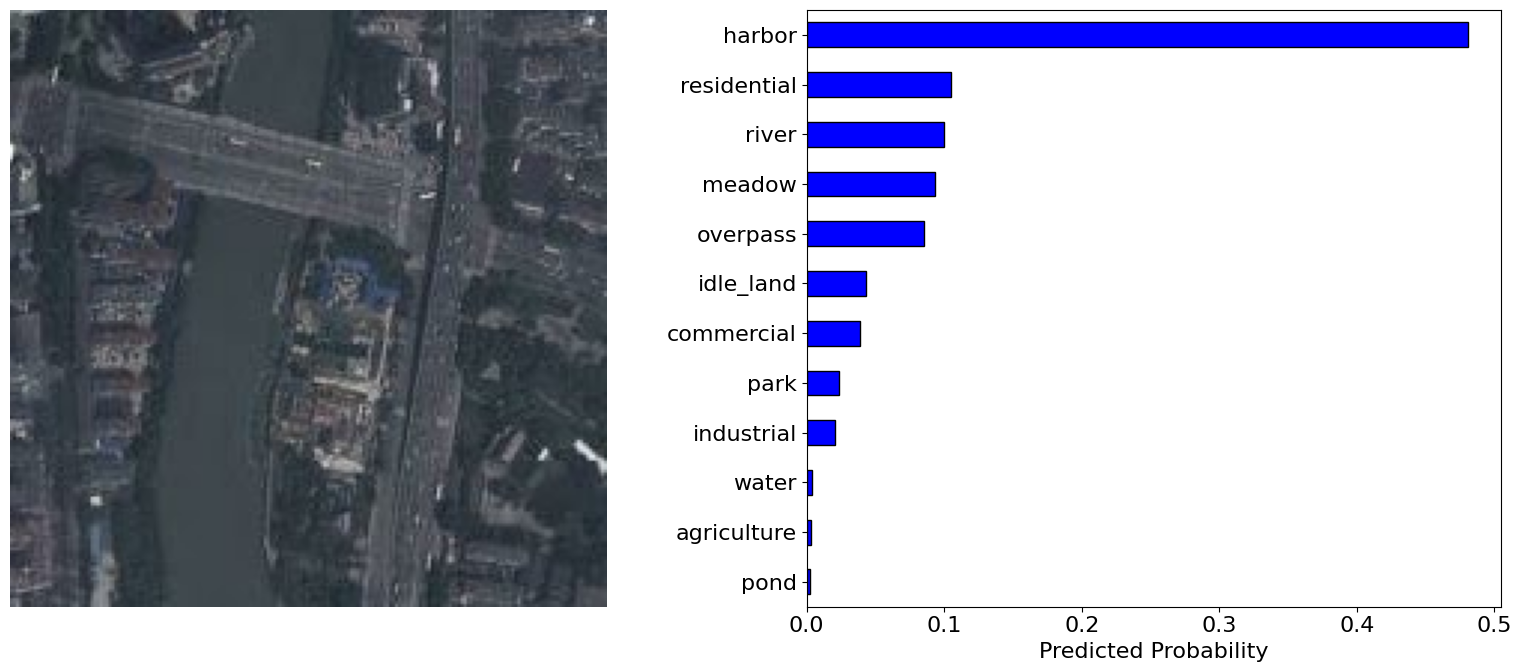

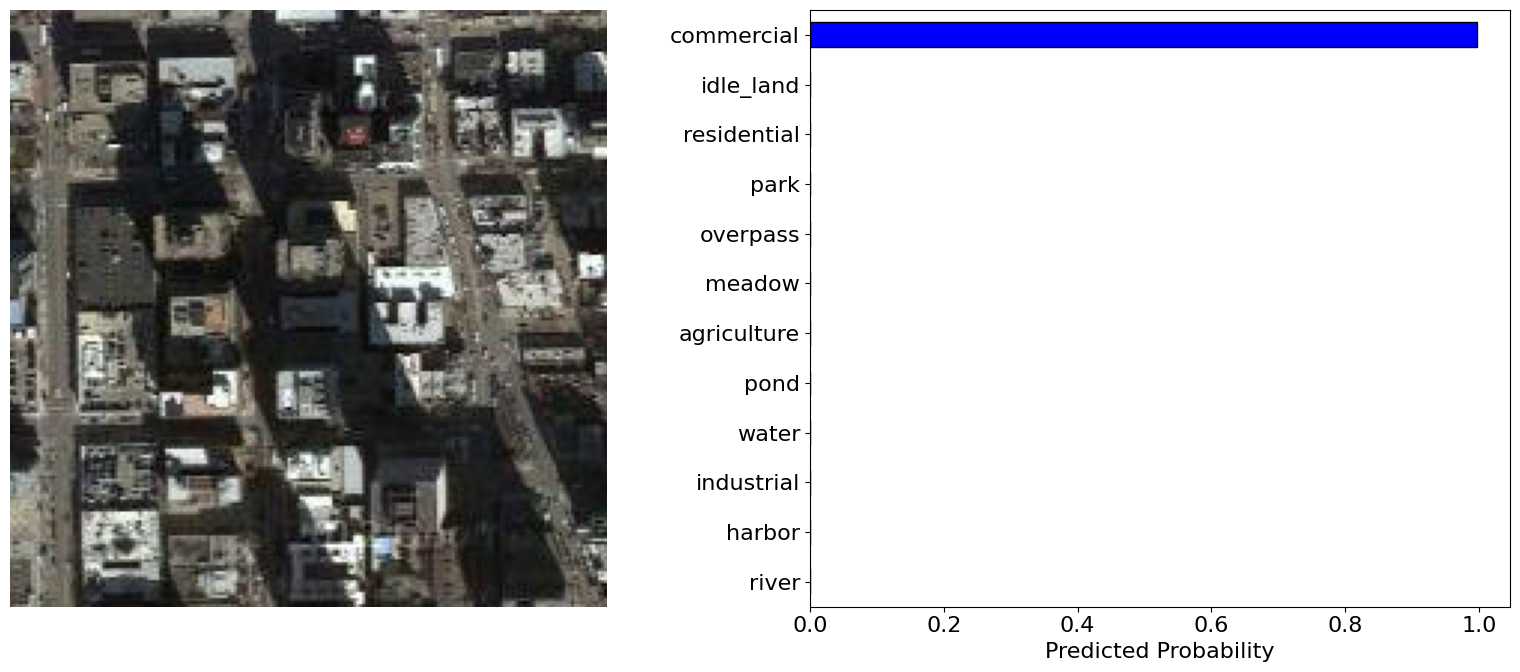

In [ ]:
model_path = "./data/experiments/SIRI-WHU/checkpoint.pth.tar"
labels = [
    "agriculture",
    "commercial",
    "harbor",
    "idle_land",
    "industrial",
    "meadow",
    "overpass",
    "park",
    "pond",
    "residential",
    "river",
    "water",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "./data/SIRI-WHU",
    "csv_file": "./data/SIRI-WHU/siriwhu_test.csv"
}

test_dataset = SiriWhuDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)